# Data Cleaning and Variable Generation

In [1]:
import pandas as pd
import numpy as np
import os
import csv
import sklearn

C:\Users\ohdaw\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Allowed INFLOW_CD values
allowed_codes = [
    11110, 11140, 11170, 11200, 11215, 11230,
    11260, 11290, 11305, 11320, 11350, 11380,
    11410, 11440, 11470, 11500, 11530, 11545,
    11560, 11590, 11620, 11650, 11680, 11710,
    11740
]

# ✅ Input folder containing all monthly files
input_dir = r"D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터"

# ✅ Output folder
output_dir = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo"

# ✅ Create output folder if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# ✅ Output file name
output_file = os.path.join(output_dir, "ALL_Filtered_Output_2019.csv")

# List to store filtered DataFrames
all_filtered_data = []

# ✅ Loop through months 201901 → 201912
for month in range(1, 13):

    ym = f"2019{month:02d}"   # makes 201901, 201902, ... 201912
    filename = f"Seoul_Park_{ym}.csv"
    file_path = os.path.join(input_dir, filename)

    print("Processing:", file_path)

    # ✅ Read file
    df = pd.read_csv(file_path, sep="|")

    # ✅ Ensure INFLOW_CD is integer
    df["INFLOW_CD"] = df["INFLOW_CD"].astype(int)

    # ✅ Filter rows
    filtered_df = df[df["INFLOW_CD"].isin(allowed_codes)]

    # Append filtered result
    all_filtered_data.append(filtered_df)

# ✅ Combine all months into one DataFrame
final_df = pd.concat(all_filtered_data, ignore_index=True)

# ✅ Save final combined file
final_df.to_csv(output_file, index=False, sep="|")

print("\n✅ Done!")
print("Combined file saved at:")
print(output_file)
print("Total rows:", len(final_df))

Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201901.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201902.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201903.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201904.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201905.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201906.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201907.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201908.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201909.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201910.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201911.csv
Processing: D:\Dropbox\Dropbox\SNU\covid\데이터\2019년 서울시 공원 데이터\Seoul_Park_201

In [3]:
# File paths
origin_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\origin_latlong.csv"
park_file   = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_latlong.csv"

# ✅ Load with Korean encoding
origin_df = pd.read_csv(origin_file, encoding="CP949")
park_df   = pd.read_csv(park_file, encoding="utf-8")

# ✅ Merge 1: on INFLOW_CD
merged_df = final_df.merge(
    origin_df,
    on="INFLOW_CD",
    how="left",
    suffixes=("", "_origin")
)

# ✅ Merge 2: on ID
merged_df = merged_df.merge(
    park_df,
    on="ID",
    how="left",
    suffixes=("", "_park")
)

# ✅ Remove duplicate columns (optional)
merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

merged_df = merged_df.drop(
    columns=[col for col in merged_df.columns if col.endswith("_origin") or col.endswith("_park")]
)

print(merged_df.head(30))

    ID  STD_YM   STD_YMD PARK_NAME  INFLOW_CD   M_0009  M_1014  M_1519  \
0    1  201901  20190101       중랑천      11110     2.47    0.94    9.24   
1    1  201901  20190101       중랑천      11140     2.12    3.36    9.51   
2    1  201901  20190101       중랑천      11170     1.19    1.92   10.10   
3    1  201901  20190101       중랑천      11200   247.12  166.54  361.27   
4    1  201901  20190101       중랑천      11215   112.70   39.41   97.57   
5    1  201901  20190101       중랑천      11230   492.99  238.40  379.36   
6    1  201901  20190101       중랑천      11260   330.61  158.60  405.47   
7    1  201901  20190101       중랑천      11290   224.45  104.94  229.25   
8    1  201901  20190101       중랑천      11305    18.22    6.34   58.83   
9    1  201901  20190101       중랑천      11320   392.38  212.85  574.57   
10   1  201901  20190101       중랑천      11350  1149.20  599.09  964.73   
11   1  201901  20190101       중랑천      11380     0.75    1.48   15.00   
12   1  201901  20190101       중랑천    

In [4]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_JOINED_OUTPUT_utf8.csv"

merged_df.to_csv(output_path, index=False, encoding="utf-8")


In [5]:
# Annual Sum

merged_df_summed = (
    merged_df
    .drop(columns=["STD_YM", "STD_YMD", "????"])   # remove STD_YMD first
    .groupby(["ID", "PARK_NAME", "INFLOW_CD", "DO_GU", "lat", "long", "Latitude", "Longitude"], as_index=False)
    .sum()
)

In [153]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_JOINED_OUTPUT_SUM_utf8.csv"

merged_df_summed.to_csv(output_path, index=False, encoding="utf-8")

In [6]:
import osmnx as ox
import networkx as nx

In [ ]:
df_pairs = merged_df_summed

# df_pairs: your 6925 OD rows
all_points = pd.concat([
    df_pairs[['lat','long']].rename(columns={'lat':'lat1','long':'long1'}),
    df_pairs[['Latitude','Longitude']].rename(columns={'Latitude':'lat1','Longitude':'long1'})
], ignore_index=True)

north, south = all_points['lat1'].max(), all_points['lat1'].min()
east, west   = all_points['long1'].max(), all_points['long1'].min()

# Expand a bit (meters)
G_walk  = ox.graph_from_bbox(north, south, east, west, network_type="walk",  simplify=True)
G_drive = ox.graph_from_bbox(north, south, east, west, network_type="drive", simplify=True)

# Project to a metric CRS for faster nearest-node and reliable geometry ops
G_walk  = ox.project_graph(G_walk)
G_drive = ox.project_graph(G_drive)
#G_drive = ox.graph_from_place(["Seoul, South Korea", "Gyeonggi-do, South Korea"], network_type="drive")

In [ ]:
# Unique origin points (dong centroids)
orig = (df_pairs[['INFLOW_CD','lat','long']]
        .drop_duplicates('INFLOW_CD')
        .reset_index(drop=True))

# Unique park points
park = (df_pairs[['ID','Latitude','Longitude']]
        .drop_duplicates('ID')
        .reset_index(drop=True))

def snap_nodes(G, lat_col, lon_col, df):
    # OSMnx expects X=lon, Y=lat in *unprojected*; but with projected graphs, nearest_nodes expects x/y in graph CRS.
    # So we convert points to GeoSeries in the graph CRS, then pass x/y.
    gdf = ox.geocode_to_gdf("Seoul, South Korea")  # not used; just to access ox utils? (skip)


In [ ]:
import geopandas as gpd
from shapely.geometry import Point

def snap_nodes_projected(G, df, lat_col, lon_col):
    # graph CRS
    crs_graph = G.graph['crs']
    gdf = gpd.GeoDataFrame(
        df.copy(),
        geometry=[Point(xy) for xy in zip(df[lon_col], df[lat_col])],
        crs="EPSG:4326"
    ).to_crs(crs_graph)
    x = gdf.geometry.x.to_numpy()
    y = gdf.geometry.y.to_numpy()
    nodes = ox.distance.nearest_nodes(G, X=x, Y=y)
    return pd.Series(nodes, index=df.index)

orig['node_walk']  = snap_nodes_projected(G_walk,  orig, 'lat', 'long')
orig['node_drive'] = snap_nodes_projected(G_drive, orig, 'lat', 'long')

park['node_walk']  = snap_nodes_projected(G_walk,  park, 'Latitude','Longitude')
park['node_drive'] = snap_nodes_projected(G_drive, park, 'Latitude','Longitude')

In [ ]:
df = df_pairs.merge(orig[['INFLOW_CD','node_walk','node_drive']], on='INFLOW_CD', how='left')
df = df.merge(park[['ID','node_walk','node_drive']].rename(columns={
    'node_walk':'park_node_walk',
    'node_drive':'park_node_drive'
}), on='ID', how='left')

In [ ]:
def shortest_lengths_by_origin(G, df, origin_col, dest_col, weight="length", cutoff=None):
    """
    Returns a numpy array of shortest path lengths for each row in df.
    Groups by origin; runs single-source Dijkstra once per unique origin.
    """
    out = np.full(len(df), np.nan, dtype=float)

    # map row indices by origin
    for o, sub_idx in df.groupby(origin_col).groups.items():
        dest_nodes = df.loc[sub_idx, dest_col].to_numpy()
        dest_set = set(dest_nodes)

        try:
            # Single-source Dijkstra
            lengths = nx.single_source_dijkstra_path_length(G, o, weight=weight, cutoff=cutoff)
        except Exception:
            continue

        # Fill outputs
        out[sub_idx] = [lengths.get(d, np.nan) for d in dest_nodes]

    return out

# Optional cutoff in meters to speed up; set None if unsure.
# For Seoul, a cutoff like 50000 (50 km) is usually safe.
CUTOFF = 700000

df['dist_walk_m']  = shortest_lengths_by_origin(G_walk,  df, 'node_walk',  'park_node_walk',  cutoff=CUTOFF)
df['dist_drive_m'] = shortest_lengths_by_origin(G_drive, df, 'node_drive', 'park_node_drive', cutoff=CUTOFF)

In [ ]:
V_WALK_KMPH  = 4.8
V_DRIVE_KMPH = 22.0  # rough urban average; you can sensitivity-test

df['time_walk_min']  = (df['dist_walk_m']  / 1000) / V_WALK_KMPH  * 60
df['time_drive_min'] = (df['dist_drive_m'] / 1000) / V_DRIVE_KMPH * 60

In [ ]:
def logsum_equiv_cost(cw, cd, lam=0.1, theta_w=0.0, theta_d=0.0):
    """
    Equivalent cost from 2-mode logsum:
      c_eq = -(1/lam) * log( exp(theta_w - lam*cw) + exp(theta_d - lam*cd) )
    cw, cd can be numpy arrays (minutes or meters), same units.
    """
    cw = np.asarray(cw, dtype=float)
    cd = np.asarray(cd, dtype=float)

    # Handle NaNs: if one mode missing, fall back to the other
    c_eq = np.full_like(cw, np.nan)

    both = np.isfinite(cw) & np.isfinite(cd)
    only_w = np.isfinite(cw) & ~np.isfinite(cd)
    only_d = ~np.isfinite(cw) & np.isfinite(cd)

    # stable log-sum-exp
    a = theta_w - lam*cw[both]
    b = theta_d - lam*cd[both]
    m = np.maximum(a, b)
    c_eq[both] = -(1/lam) * (m + np.log(np.exp(a - m) + np.exp(b - m)))

    c_eq[only_w] = cw[only_w]
    c_eq[only_d] = cd[only_d]
    return c_eq

df['c_eq_min'] = logsum_equiv_cost(df['time_walk_min'], df['time_drive_min'], lam=0.1)

In [ ]:
print(df[['dist_walk_m','dist_drive_m','time_walk_min','time_drive_min','c_eq_min']].describe())

# How many missing?
print(df[['dist_walk_m','dist_drive_m']].isna().mean())

In [ ]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dist_logsum.csv"
df = df.drop(columns=["PARK_NAME", "DO_GU", "lat", "long", "Latitude", "Longitude", "orig_in_cc", "park_in_cc", 
"node_walk", "node_drive", "park_node_walk", "park_node_drive"]) 

df.to_csv(output_path, index=False, encoding="utf-8")

In [3]:
# File paths
df_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dist_logsum.csv"

# ✅ Load with Korean encoding
df = pd.read_csv(df_file, encoding="CP949")

In [4]:
# File paths
parkvar_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_var.csv"
greenarea_file   = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_greenarea_rat.csv"

# ✅ Load with Korean encoding
parkvar_df = pd.read_csv(parkvar_file, encoding="CP949")
greenarea_df   = pd.read_csv(greenarea_file, encoding="utf-8")

# Make ID consistent (string) across all dfs
df["ID"] = df["ID"].astype(str).str.strip()
parkvar_df["ID"] = parkvar_df["ID"].astype(str).str.strip()
greenarea_df["ID"] = greenarea_df["ID"].astype(str).str.strip()


# ✅ Merge 1: park variable
merge_df1 = df.merge(
    parkvar_df,
    on="ID",
    how="left",
    suffixes=("", "_parkvar")
)

# ✅ Merge 2:green area
merged_df1 = merge_df1.merge(
    greenarea_df,
    on="ID",
    how="left",
    suffixes=("", "_greenarea")
)

# ✅ Remove duplicate columns (optional)
merged_df1 = merged_df1.loc[:, ~merged_df1.columns.duplicated()]
merged_df1 = merged_df1.drop(columns=[c for c in merged_df1.columns
                                    if c.endswith("_parkvar") or c.endswith("_greenarea")])


print(merged_df1.head(30))

   ID  INFLOW_CD     M_0009     M_1014     M_1519     M_2024     M_2529  \
0   1      11110    2743.79    1295.46    5250.84    9011.49   11209.37   
1   1      11140    3067.71    2442.97    4872.58   12522.09   15656.14   
2   1      11170    3591.36    1905.94    5230.97    9095.59   16085.98   
3   1      11200  133752.70   95632.90  157997.87  216959.75  244180.36   
4   1      11215   64066.00   28410.62   55027.84  101552.79  141508.00   
5   1      11230  275542.79  151796.74  224199.57  224705.83  293643.12   
6   1      11260  185919.87  113038.70  222781.14  299810.93  353003.23   
7   1      11290  113714.39   65442.38  115971.92  180338.02  174443.59   
8   1      11305   16980.26    7924.88   27911.56   51083.51   64884.24   
9   1      11320  193111.94  123831.97  251288.38  247793.64  279380.36   
10  1      11350  614444.67  368386.99  542784.96  630190.36  671469.55   
11  1      11380    3593.02    1723.07    6517.19   16763.96   16476.03   
12  1      11410    2743.

In [5]:
# File paths
transit_file = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\park_bussub.csv"

# ✅ Load with Korean encoding
trnasit_df = pd.read_csv(transit_file, encoding="CP949")

# Make ID consistent (string) across all dfs
merged_df1["ID"] = merged_df1["ID"].astype(str).str.strip()
trnasit_df["ID"] = trnasit_df["ID"].astype(str).str.strip()


# ✅ Merge 1: park variable
merged_df2 = merged_df1.merge(
    trnasit_df,
    on="ID",
    how="left",
    suffixes=("", "_transit")
)

# ✅ Remove duplicate columns (optional)
merged_df2 = merged_df2.loc[:, ~merged_df2.columns.duplicated()]
merged_df2 = merged_df2.drop(columns=[c for c in merged_df2.columns
                                    if c.endswith("_transit")])


print(merged_df2.head(30))

   ID  INFLOW_CD     M_0009     M_1014     M_1519     M_2024     M_2529  \
0   1      11110    2743.79    1295.46    5250.84    9011.49   11209.37   
1   1      11140    3067.71    2442.97    4872.58   12522.09   15656.14   
2   1      11170    3591.36    1905.94    5230.97    9095.59   16085.98   
3   1      11200  133752.70   95632.90  157997.87  216959.75  244180.36   
4   1      11215   64066.00   28410.62   55027.84  101552.79  141508.00   
5   1      11230  275542.79  151796.74  224199.57  224705.83  293643.12   
6   1      11260  185919.87  113038.70  222781.14  299810.93  353003.23   
7   1      11290  113714.39   65442.38  115971.92  180338.02  174443.59   
8   1      11305   16980.26    7924.88   27911.56   51083.51   64884.24   
9   1      11320  193111.94  123831.97  251288.38  247793.64  279380.36   
10  1      11350  614444.67  368386.99  542784.96  630190.36  671469.55   
11  1      11380    3593.02    1723.07    6517.19   16763.96   16476.03   
12  1      11410    2743.

In [6]:
print("Before:", len(merged_df2))
merged_df3 = merged_df2.dropna()
print("After:", len(merged_df3))

Before: 10600
After: 6850


In [12]:
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
merged_df3.to_csv(output_path, index=False, encoding="utf-8")

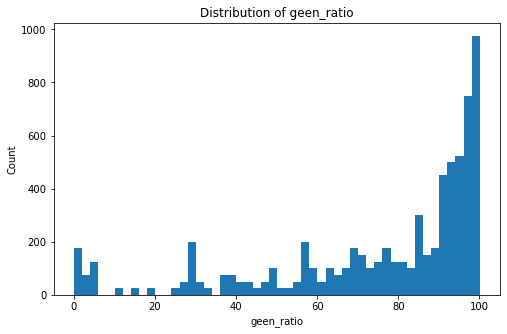

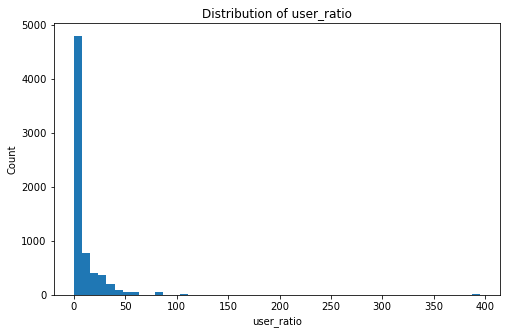

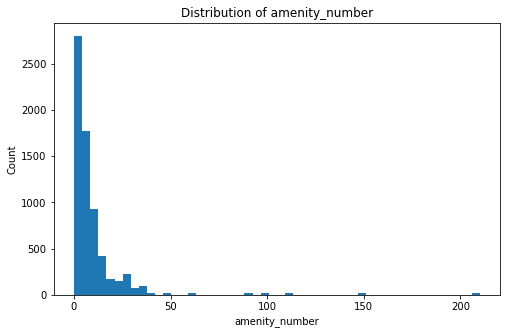

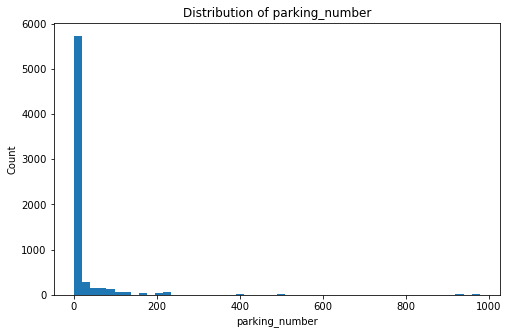

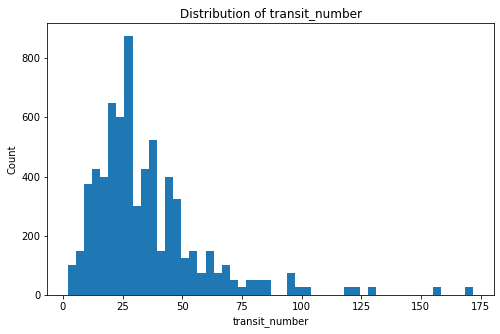

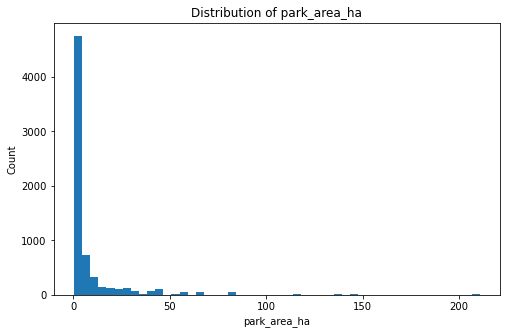

In [7]:
import matplotlib.pyplot as plt

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
merged_df3 = pd.read_csv(output_path, encoding="utf-8")

["parkinglot_number", "parkingcapacity_number", "parkinglot_area", "opensapce_number", 
                "openspaace_area", "road_number", "road_area", "walkingtrail_number", "walkingtrail_area", 
                "plantbed_number", "plantbed_area", "pond_number", "pond_area", "campingsite_number", 
                "campingsite_area", "shadecanopy_number", "shadecanopy_area", "playground_number", 
                "gymtrack_number", "gymtrack_area", "swimmingpool_number", "swimmingpool_area", 
                "sportsfacility_number", "communitycenter_number", "communitycenter_area", "musichall_number", 
                "cafeteria_number", "cafeteria_area", "kiosk_number", "kiosk_area", "greenarea_area", 
                "park_area", "bus500", "bus100", "sub500", "sub100"]


area_vars = ["park_area"]
merged_df3[[a + "_ha" for a in area_vars]] = merged_df3[area_vars] / 10_000

merged_df3["geen_ratio"] = merged_df3["greenarea_area"] / merged_df3["park_area"] *100

merged_df3["user_area"] = (
      merged_df3["openspaace_area"]
    + merged_df3["road_area"]
    + merged_df3["walkingtrail_area"]
    + merged_df3["shadecanopy_area"]
)
merged_df3["user_ratio"] = merged_df3["user_area"] / merged_df3["park_area"] * 100

merged_df3["amenity_number"] = (
      merged_df3["gymtrack_number"]
    + merged_df3["swimmingpool_number"]
    + merged_df3["sportsfacility_number"]
    + merged_df3["playground_number"]
    + merged_df3["cafeteria_number"]
    + merged_df3["kiosk_number"]
)

merged_df3["parking_number"] = merged_df3["parkingcapacity_number"]

merged_df3["transit_number"] = merged_df3["bus500"] + merged_df3["sub500"]

vars_to_plot = ["geen_ratio", "user_ratio", "amenity_number", "parking_number","transit_number", "park_area_ha"]

for var in vars_to_plot:
    x = merged_df3[var].dropna()

    plt.figure(figsize=(8,5))
    plt.hist(x, bins=50)

    plt.title(f"Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Count")

    plt.show()

# Compute Accessibility

In [14]:
import re
from scipy.special import logsumexp

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
dt = pd.read_csv(output_path, encoding="utf-8")

# demographic columns like M_0009, W_1014, ...
group_cols = [c for c in dt.columns if re.match(r'^[MW]_\d{4}$', c)]

# basic sanity
assert "INFLOW_CD" in dt.columns
assert "ID" in dt.columns
assert "c_eq_min" in dt.columns

In [15]:
beta = 0.10  # try 0.05, 0.10, 0.20 as sensitivity

# term inside logsumexp: -beta * cost
df["u"] = -beta * df["c_eq_min"]

A_origin = (
    df.groupby("INFLOW_CD")["u"]
      .apply(lambda x: logsumexp(x.values))
      .reset_index(name="A_logsum")
)

print(A_origin.head())

   INFLOW_CD  A_logsum
0      11110  3.291949
1      11140  3.770290
2      11170  3.605955
3      11200  3.636711
4      11215  3.411106


In [18]:
# Example supply weight: park_area (must be >0)
# If park_area repeats by origin (it will), that's fine.

eps = 1e-6
#df["logS"] = np.log(df["park_area"].clip(lower=eps))
#df["u_supply"] = df["logS"] - beta * df["c_eq_min"]

A_origin_supply = (
    df.groupby("INFLOW_CD")["u_supply"]
      .apply(lambda x: logsumexp(x.values))
      .reset_index(name="A_logsum_supply")
)

KeyError: 'park_area'

In [19]:
# total visitors by origin for each group
origin_group_totals = df.groupby("INFLOW_CD")[group_cols].sum().reset_index()

# merge origin accessibility
origin_stats = origin_group_totals.merge(A_origin, on="INFLOW_CD", how="left")

rows = []
for g in group_cols:
    w = origin_stats[g].to_numpy()
    A = origin_stats["A_logsum"].to_numpy()
    rows.append((g, np.average(A, weights=w)))

group_access = pd.DataFrame(rows, columns=["group", "A_logsum_weighted"])
group_access = group_access.sort_values("A_logsum_weighted", ascending=False)

print(group_access.head(10))

     group  A_logsum_weighted
19  W_3034           3.422007
20  W_3539           3.421197
21  W_4044           3.420211
15  W_1014           3.419474
1   M_1014           3.419351
22  W_4549           3.419187
18  W_2529           3.416170
14  W_0009           3.415947
16  W_1519           3.415559
4   M_2529           3.414450


In [20]:
rows = []
c = df["c_eq_min"].to_numpy()

for g in group_cols:
    w = df[g].to_numpy()
    mask = np.isfinite(c) & (w > 0)
    rows.append((g, np.average(c[mask], weights=w[mask])))

group_realized_cost = pd.DataFrame(rows, columns=["group", "mean_c_eq_min_realized"])
group_realized_cost = group_realized_cost.sort_values("mean_c_eq_min_realized")

print(group_realized_cost.head(10))   # groups traveling least (on average)
print(group_realized_cost.tail(10))   # groups traveling most (on average)

     group  mean_c_eq_min_realized
0   M_0009               27.988728
14  W_0009               28.249624
27  W_7000               28.370745
1   M_1014               28.523893
26  W_6569               28.529406
15  W_1014               28.692702
25  W_6064               28.894833
13  M_7000               28.918493
2   M_1519               29.040232
24  W_5559               29.310722
     group  mean_c_eq_min_realized
3   M_2024               30.700529
10  M_5559               30.761768
9   M_5054               31.211781
17  W_2024               31.344363
4   M_2529               31.359466
6   M_3539               31.377937
18  W_2529               31.392010
8   M_4549               31.407691
7   M_4044               31.439676
5   M_3034               31.601980


In [21]:
def compute_A_origin(df, beta):
    u = -beta * df["c_eq_min"].to_numpy()
    tmp = df[["INFLOW_CD"]].copy()
    tmp["u"] = u
    return tmp.groupby("INFLOW_CD")["u"].apply(lambda x: logsumexp(x.values)).rename(f"A_beta_{beta}")

betas = [0.05, 0.10, 0.20]
A_multi = pd.concat([compute_A_origin(df, b) for b in betas], axis=1).reset_index()
print(A_multi.head())

   INFLOW_CD  A_beta_0.05  A_beta_0.1  A_beta_0.2
0      11110     4.445055    3.291949    1.767210
1      11140     4.684663    3.770290    2.832079
2      11170     4.649444    3.605955    2.178914
3      11200     4.642668    3.636711    2.534145
4      11215     4.514804    3.411106    1.938319


# Plotting Simple Accessibility

In [82]:
def parse_group(g: str):
    sex = g[0]
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    # Handle "70+" encoded as _7000 (age_hi=0) or 65-69
    if age_lo >= 65:
        age_mid = 72
    else:
        age_mid = (age_lo + age_hi) / 2
    return sex, age_lo, age_hi, age_mid

# Re-run from scratch — re-apply parse_group to get corrected age_mid
group_access[["sex", "age_lo", "age_hi", "age_mid"]] = group_access["group"].apply(
    lambda x: pd.Series(parse_group(x))
)
group_access["age_label"] = group_access["age_lo"].apply(age_lo_to_label)

# Verify before plotting
print(group_access[["group","age_lo","age_mid","age_label"]].sort_values("age_mid"))

     group  age_lo  age_mid age_label
0   M_0009       0      4.5       0-9
14  W_0009       0      4.5       0-9
1   M_1014      10     12.0     10-19
15  W_1014      10     12.0     10-19
2   M_1519      15     17.0     10-19
16  W_1519      15     17.0     10-19
3   M_2024      20     22.0     20-29
17  W_2024      20     22.0     20-29
4   M_2529      25     27.0     20-29
18  W_2529      25     27.0     20-29
5   M_3034      30     32.0     30-39
19  W_3034      30     32.0     30-39
20  W_3539      35     37.0     30-39
6   M_3539      35     37.0     30-39
7   M_4044      40     42.0     40-49
21  W_4044      40     42.0     40-49
22  W_4549      45     47.0     40-49
8   M_4549      45     47.0     40-49
9   M_5054      50     52.0     50-59
23  W_5054      50     52.0     50-59
24  W_5559      55     57.0     50-59
10  M_5559      55     57.0     50-59
11  M_6064      60     62.0     60-69
25  W_6064      60     62.0     60-69
12  M_6569      65     72.0       70+
13  M_7000  

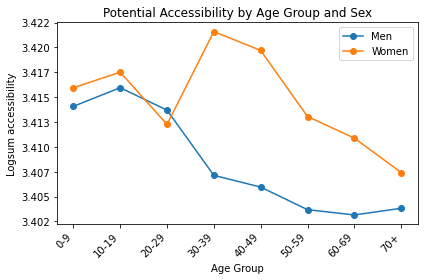

In [93]:
label_order = ["0-9","10-19","20-29","30-39","40-49","50-59","60-69","70+"]

group_access_plot = (
    group_access.groupby(["sex", "age_label"], sort=False)
    .agg(A_logsum_weighted=("A_logsum_weighted", "mean"), age_mid=("age_mid", "mean"))
    .reset_index()
    .sort_values(["sex", "age_mid"])
)

plt.figure()
sex_labels = {"M": "Men", "W": "Women"}
for sex, sub in group_access_plot.groupby("sex"):
    sub = sub.set_index("age_label").reindex(label_order).reset_index()
    plt.plot(sub["age_label"], sub["A_logsum_weighted"], marker="o", label=sex_labels.get(sex, sex))

plt.xlabel("Age Group")
plt.ylabel("Logsum accessibility")
plt.title("Potential Accessibility by Age Group and Sex")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

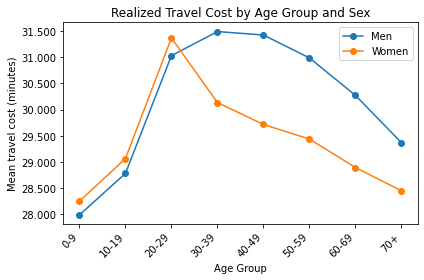

In [94]:
# -----------------------------
# Plot 2: Realized travel cost by age/sex
# (visit-weighted mean c_eq_min using OD flows)
# -----------------------------
rows = []
c = df["c_eq_min"].astype(float).to_numpy()
for g in group_cols:
    w = df[g].to_numpy()
    mask = np.isfinite(c) & (w > 0)
    if mask.sum() == 0:
        continue
    rows.append((g, np.average(c[mask], weights=w[mask])))

group_realized = pd.DataFrame(rows, columns=["group", "mean_c_eq_min_realized"])

# Parse with corrected parse_group (age_lo >= 65 → age_mid = 72)
group_realized[["sex", "age_lo", "age_hi", "age_mid"]] = group_realized["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

# Add age labels and aggregate 5-year bins into 10-year groups
group_realized["age_label"] = group_realized["age_lo"].apply(age_lo_to_label)

label_order = ["0-9","10-19","20-29","30-39","40-49","50-59","60-69","70+"]

group_realized_plot = (
    group_realized.groupby(["sex", "age_label"], sort=False)
    .agg(mean_c_eq_min_realized=("mean_c_eq_min_realized", "mean"), age_mid=("age_mid", "mean"))
    .reset_index()
    .sort_values(["sex", "age_mid"])
)

# Plot 2
plt.figure()
sex_labels = {"M": "Men", "W": "Women"}
for sex, sub in group_realized_plot.groupby("sex"):
    sub = sub.set_index("age_label").reindex(label_order).reset_index()
    plt.plot(sub["age_label"], sub["mean_c_eq_min_realized"], marker="o", label=sex_labels.get(sex, sex))

plt.xlabel("Age Group")
plt.ylabel("Mean travel cost (minutes)")
plt.title("Realized Travel Cost by Age Group and Sex")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

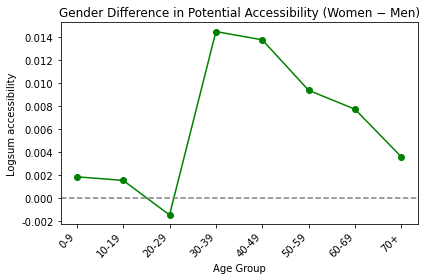

In [95]:
def prepare_diff(df, value_col):
    """
    df must contain: group, sex, age_label, age_mid, value_col
    returns dataframe with Women - Men difference by age label
    """
    wide = (
        df.pivot(index="age_label", columns="sex", values=value_col)
          .dropna(subset=["M", "W"])
          .reset_index()
    )
    # Merge age_mid back for sorting
    age_order = df[["age_label", "age_mid"]].drop_duplicates()
    wide = wide.merge(age_order, on="age_label", how="left")
    wide["W_minus_M"] = wide["W"] - wide["M"]
    return wide

label_order = ["0-9","10-19","20-29","30-39","40-49","50-59","60-69","70+"]

# Use the already-aggregated plot dataframes
diff_access = prepare_diff(group_access_plot, value_col="A_logsum_weighted")
diff_access = diff_access.set_index("age_label").reindex(label_order).reset_index()

# Plot
plt.figure()
plt.plot(
    diff_access["age_label"],
    diff_access["W_minus_M"],
    marker="o",
    color="green"
)
plt.axhline(0, linestyle="--", color="gray")
plt.xlabel("Age Group")
plt.ylabel("Logsum accessibility")
plt.title("Gender Difference in Potential Accessibility (Women − Men)")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

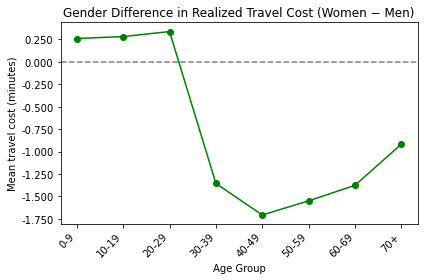

In [96]:
diff_realized = prepare_diff(group_realized_plot, value_col="mean_c_eq_min_realized")
diff_realized = diff_realized.set_index("age_label").reindex(label_order).reset_index()

# Plot
plt.figure()
plt.plot(
    diff_realized["age_label"],
    diff_realized["W_minus_M"],
    marker="o",
    color="green"
)
plt.axhline(0, linestyle="--", color="gray")
plt.xlabel("Age Group")
plt.ylabel("Mean travel cost (minutes)")
plt.title("Gender Difference in Realized Travel Cost (Women − Men)")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

# Plotting Variable Distribution

In [67]:
import statsmodels.api as sm

output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
data = pd.read_csv(output_path, encoding="utf-8")

# demographic columns
group_cols = [c for c in data.columns if re.match(r'^[MW]_\d{4}$', c)]

# -----------------------------
# Rebuild park variables
# -----------------------------
data["geen_ratio"] = data["greenarea_area"] / data["park_area"] *100

data["user_area"] = (
      data["openspaace_area"]
    + data["road_area"]
    + data["walkingtrail_area"]
    + data["shadecanopy_area"]
)
data["user_ratio"] = data["user_area"] / data["park_area"] * 100

data["amenity_number"] = (
      data["gymtrack_number"]
    + data["swimmingpool_number"]
    + data["sportsfacility_number"]
    + data["playground_number"]
    + data["cafeteria_number"]
    + data["kiosk_number"]
)

data["parking_number"] = data["parkingcapacity_number"]

data["transit_number"] = data["bus500"] + data["sub500"]

area_vars = ["park_area"]
data[[a + "_ha" for a in area_vars]] = data[area_vars] / 10_000

# Keep only simplified amenities
amenities = ["geen_ratio", "user_ratio", "amenity_number", "parking_number","transit_number", "park_area_ha"]

# -----------------------------
# Wide → Long demographic format
# -----------------------------
data_long = data.melt(
    id_vars=["INFLOW_CD", "ID", "c_eq_min"] + amenities,
    value_vars=group_cols,
    var_name="group",
    value_name="visitors"
)

# Keep only positive observed visits
data_long = data_long[data_long["visitors"] > 0].copy()

In [69]:
def parse_group(g):
    sex = 1 if g[0] == "W" else 0   # female dummy
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return sex, age_mid

data_long[["female", "age"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

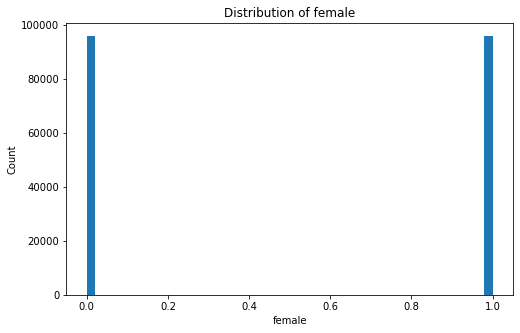

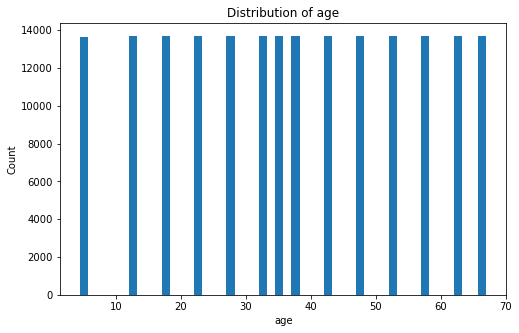

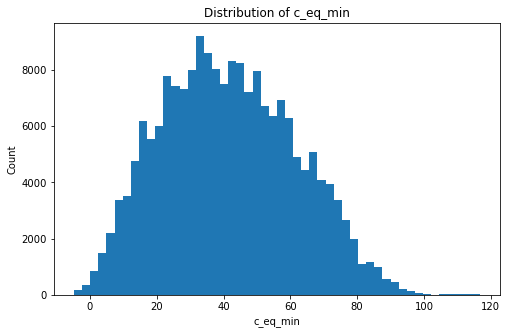

In [43]:
vars_to_plot = ["female", "age", "c_eq_min"]

for var in vars_to_plot:
    x = data_long[var].dropna()

    plt.figure(figsize=(8,5))
    plt.hist(x, bins=50)

    plt.title(f"Distribution of {var}")
    plt.xlabel(var)
    plt.ylabel("Count")

    plt.show()

# Park Amenities As Predictor Variables for The Logsum Accessibility

# Marginal Effect of Park Variables on Travel Cost\nby Age Group and Sex

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

# ─────────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────────
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
data = pd.read_csv(output_path, encoding="utf-8")

group_cols = [c for c in data.columns if re.match(r'^[MW]_\d{4}$', c)]

# ─────────────────────────────────────────────
# 2. BUILD PARK VARIABLES
# ─────────────────────────────────────────────
data["green_ratio"] = data["greenarea_area"] / data["park_area"] * 100

data["user_area"] = (
      data["openspaace_area"]
    + data["road_area"]
    + data["walkingtrail_area"]
    + data["shadecanopy_area"]
)
data["user_ratio"] = data["user_area"] / data["park_area"] * 100

data["amenity_number"] = (
      data["gymtrack_number"]
    + data["swimmingpool_number"]
    + data["sportsfacility_number"]
    + data["playground_number"]
    + data["cafeteria_number"]
    + data["kiosk_number"]
)

data["parking_number"] = data["parkingcapacity_number"]
data["transit_number"] = data["bus500"] + data["sub500"]
data["park_area_ha"]   = data["park_area"] / 10_000

amenities = ["green_ratio", "user_ratio", "amenity_number",
             "parking_number", "transit_number", "park_area_ha"]

# ─────────────────────────────────────────────
# 3. WIDE → LONG
# ─────────────────────────────────────────────
data_long = data.melt(
    id_vars=["INFLOW_CD", "ID", "c_eq_min"] + amenities,
    value_vars=group_cols,
    var_name="group",
    value_name="visitors"
)
data_long = data_long[data_long["visitors"] > 0].copy()

# ─────────────────────────────────────────────
# 4. PARSE SEX & AGE
# ─────────────────────────────────────────────
def parse_group(g):
    female = 1 if g[0] == "W" else 0
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return female, age_mid

data_long[["female", "age"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

# ─────────────────────────────────────────────
# 5. DERIVED VARIABLES & INTERACTIONS (raw age)
# ─────────────────────────────────────────────
data_long["age_sq"] = data_long["age"] ** 2          # raw age squared

for a in amenities:
    data_long[f"{a}_F"]   = data_long[a] * data_long["female"]
    data_long[f"{a}_A"]   = data_long[a] * data_long["age"]      # raw age
    data_long[f"{a}_FA"]  = data_long[a] * data_long["female"] * data_long["age"]
    data_long[f"{a}_A2"]  = data_long[a] * data_long["age_sq"]
    data_long[f"{a}_FA2"] = data_long[a] * data_long["female"] * data_long["age_sq"]

# ─────────────────────────────────────────────
# 6. ORIGIN DUMMIES
# ─────────────────────────────────────────────
origin_dummies = pd.get_dummies(
    data_long["INFLOW_CD"].astype(str),
    prefix="orig",
    drop_first=True
).astype(int).reset_index(drop=True)

print(f"Origin dummies added : {origin_dummies.shape[1]}")
print(f"Reference origin     : {data_long['INFLOW_CD'].astype(str).unique()[0]}\n")

# ─────────────────────────────────────────────
# 7. FIT CCREM VIA rpy2 (replaces WLS + origin dummies)
# ─────────────────────────────────────────────
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, default_converter
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

# Load required R packages (install once in R: install.packages(c("lme4","performance")))
lme4 = importr("lme4")

# Push data_long into R's global environment
with localconverter(default_converter + pandas2ri.converter):
    ro.globalenv["data_long"] = ro.conversion.py2rpy(data_long)

# Same fixed-effects spec as your WLS model, minus origin dummies —
# origin is now a random effect instead of a fixed one
fixed_vars_sq = (
    ["female", "age", "age_sq"]
    + amenities
    + [f"{a}_F"   for a in amenities]
    + [f"{a}_A"   for a in amenities]
    + [f"{a}_FA"  for a in amenities]
    + [f"{a}_A2"  for a in amenities]
    + [f"{a}_FA2" for a in amenities]
)

formula_str = "c_eq_min ~ " + " + ".join(fixed_vars_sq) + " + (1|ID) + (1|INFLOW_CD)"
ro.globalenv["formula_str"] = formula_str

ro.r('''
ccrem <- lmer(
  as.formula(formula_str),
  data = data_long,
  weights = visitors,
  control = lmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 2e5))
)
''')

print("Model fit complete.\n")

# ─────────────────────────────────────────────
# 8. DIAGNOSTICS + PULL RESULTS BACK INTO PYTHON
# ─────────────────────────────────────────────

# --- 8a. Convergence / singularity checks ---
ro.r('''
cat("=== isSingular ===\n")
print(isSingular(ccrem))

cat("\n=== VarCorr (variance components) ===\n")
print(VarCorr(ccrem))

cat("\n=== rePCA (which RE dimension is degenerate) ===\n")
print(summary(rePCA(ccrem)))
''')

# Optional but recommended: cross-optimizer check (slower — comment out if it's too slow)
run_allfit_check = True
if run_allfit_check:
    ro.r('''
    af <- allFit(ccrem)
    cat("\n=== allFit: which optimizers converged OK ===\n")
    print(summary(af)$which.OK)
    cat("\n=== allFit: fixed effects across optimizers (amenity vars) ===\n")
    print(summary(af)$fixef)
    ''')

# --- 8b. Pull fixed-effect estimates, SEs, p-values (Satterthwaite via lmerTest, or Wald as fallback) ---
ro.r('''
# Wald-based summary (works without lmerTest)
s <- summary(ccrem)
coefs <- as.data.frame(s$coefficients)
coefs$term <- rownames(coefs)
rownames(coefs) <- NULL
''')

with localconverter(default_converter + pandas2ri.converter):
    ccrem_coefs = ro.conversion.rpy2py(ro.r("coefs"))

ccrem_coefs = ccrem_coefs.rename(columns={
    "Estimate": "Estimate",
    "Std. Error": "SE",
    "t value": "t_stat"
})
ccrem_coefs["z_or_t"] = ccrem_coefs["Estimate"] / ccrem_coefs["SE"]
ccrem_coefs["p_value"] = 2 * (1 - stats.norm.cdf(np.abs(ccrem_coefs["z_or_t"])))
ccrem_coefs = ccrem_coefs.set_index("term")

def sig_stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    elif p < 0.1:  return "."
    else:          return ""

ccrem_coefs["Sig"] = ccrem_coefs["p_value"].apply(sig_stars)

print("\n─── CCREM Fixed Effects (substantive vars only) ───")
substantive = [v for v in ccrem_coefs.index if v != "(Intercept)"]
print(ccrem_coefs.loc[substantive, ["Estimate", "SE", "t_stat", "p_value", "Sig"]].round(6).to_string())

# --- 8c. Pull variance components into a Python dict for later reporting ---
with localconverter(default_converter + pandas2ri.converter):
    varcorr_df = ro.conversion.rpy2py(ro.r('''
    vc <- as.data.frame(VarCorr(ccrem))
    vc
    '''))

print("\n─── Variance Components ───")
print(varcorr_df.to_string())

# ─────────────────────────────────────────────
# 9. DISPLAY RESULTS (substantive vars only)
# ─────────────────────────────────────────────
non_fe_mask  = [not v.startswith("orig_") for v in X_full.columns]
display_vars = [v for v in X_full.columns if not v.startswith("orig_")]

params_display = res_ore_sq.params[non_fe_mask]
se_display     = clustered_se[non_fe_mask]
tvals          = params_display.values / se_display
pvals          = 2 * (1 - stats.t.cdf(np.abs(tvals), df=n_parks - 1))
ci_low         = params_display.values - 1.96 * se_display
ci_hi          = params_display.values + 1.96 * se_display

def sig_stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    elif p < 0.1:  return "."
    else:          return ""

results_df = pd.DataFrame({
    "Estimate":   params_display.values.round(6),
    "Cluster_SE": se_display.round(6),
    "t_stat":     tvals.round(3),
    "p_value":    pvals.round(3),
    "[0.025":     ci_low.round(6),
    "0.975]":     ci_hi.round(6),
    "Sig":        [sig_stars(p) for p in pvals]
}, index=display_vars)

print("─── Origin FE + Age² + Park-Clustered SEs (substantive vars only) ───")
print(results_df.to_string())

# ─────────────────────────────────────────────
# 10. MARGINAL EFFECTS (raw age)
# ─────────────────────────────────────────────
coefs_ore_sq = res_ore_sq.params

age_groups = {
    "0–9":   5,
    "10–19": 15,
    "20–29": 25,
    "30–39": 35,
    "40–49": 45,
    "50–59": 55,
    "60–69": 65,
    "70+":   75
}

def marginal_effect_sq(coefs, var, age, female):
    age_sq = age ** 2                    # raw age squared
    b    = coefs.get(var,           0)
    bf   = coefs.get(f"{var}_F",    0)
    ba   = coefs.get(f"{var}_A",    0)
    bfa  = coefs.get(f"{var}_FA",   0)
    ba2  = coefs.get(f"{var}_A2",   0)
    bfa2 = coefs.get(f"{var}_FA2",  0)
    return (b
            + female * bf
            + age    * ba
            + female * age    * bfa
            + age_sq * ba2
            + female * age_sq * bfa2)

rows = []
for var in amenities:
    for label, age in age_groups.items():
        me_m = marginal_effect_sq(coefs_ore_sq, var, age, female=0)
        me_w = marginal_effect_sq(coefs_ore_sq, var, age, female=1)
        rows.append({
            "Amenity":      var,
            "AgeGroup":     label,
            "AgeMid":       age,
            "Men_Effect":   me_m,
            "Women_Effect": me_w,
            "W_minus_M":    me_w - me_m
        })

marginal_table_sq = pd.DataFrame(rows)
print("\n─── Marginal Effects by Age Group and Sex (Origin FE + Age²) ───")
print(marginal_table_sq.to_string(index=False))

# ─────────────────────────────────────────────
# 11. PLOT
# ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, var in enumerate(amenities):
    ax  = axes[i]
    sub = marginal_table_sq[marginal_table_sq["Amenity"] == var]

    ax.plot(sub["AgeGroup"], sub["Men_Effect"],   marker="o", label="Men",   color="steelblue")
    ax.plot(sub["AgeGroup"], sub["Women_Effect"], marker="s", label="Women", color="tomato")
    ax.axhline(0, linestyle="--", color="gray", linewidth=0.8)

    ax.set_title(var, fontsize=11)
    ax.set_ylabel("Effect on travel cost (min)")
    ax.set_xlabel("Age Group")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

plt.suptitle(
    "Marginal Effect of Park Variables on Travel Cost\n"
    "by Age Group and Sex (Origin FE + Age², Park-Clustered SEs)",
    fontsize=13
)
plt.tight_layout()
plt.savefig("marginal_effects_origin_fe_agesq.png", dpi=150, bbox_inches="tight")
plt.show()

Origin dummies added : 24
Reference origin     : 11110



ModuleNotFoundError: No module named 'rpy2'

In [4]:
print(res_ore_sq.summary())

                            WLS Regression Results                            
Dep. Variable:               c_eq_min   R-squared:                       0.273
Model:                            WLS   Adj. R-squared:                  0.272
Method:                 Least Squares   F-statistic:                     1140.
Date:                Tue, 07 Jul 2026   Prob (F-statistic):               0.00
Time:                        19:14:59   Log-Likelihood:            -1.0924e+06
No. Observations:              191750   AIC:                         2.185e+06
Df Residuals:                  191686   BIC:                         2.186e+06
Df Model:                          63                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 46.0768      0

In [6]:
import pandas as pd
import numpy as np
import re

# ─────────────────────────────────────────────
# 1. LOAD DATA (same as your script)
# ─────────────────────────────────────────────
output_path = r"C:\Users\ohdaw\OneDrive - Harvard University\snu_remains\redo\FINAL_dataset_2019only.csv"
data = pd.read_csv(output_path, encoding="utf-8")

group_cols = [c for c in data.columns if re.match(r'^[MW]_\d{4}$', c)]
print(f"Wide data shape: {data.shape}")
print(f"Age-sex group columns found: {len(group_cols)}")
print(f"Unique ID (parks): {data['ID'].nunique()}")
print(f"Unique INFLOW_CD (origins): {data['INFLOW_CD'].nunique()}")
print()

# ─────────────────────────────────────────────
# BUILD PARK VARIABLES (same as your script)
# ─────────────────────────────────────────────
data["green_ratio"] = data["greenarea_area"] / data["park_area"] * 100

data["user_area"] = (
      data["openspaace_area"]
    + data["road_area"]
    + data["walkingtrail_area"]
    + data["shadecanopy_area"]
)
data["user_ratio"] = data["user_area"] / data["park_area"] * 100

data["amenity_number"] = (
      data["gymtrack_number"]
    + data["swimmingpool_number"]
    + data["sportsfacility_number"]
    + data["playground_number"]
    + data["cafeteria_number"]
    + data["kiosk_number"]
)

data["parking_number"] = data["parkingcapacity_number"]
data["transit_number"] = data["bus500"] + data["sub500"]
data["park_area_ha"]   = data["park_area"] / 10_000

amenities = ["green_ratio", "user_ratio", "amenity_number",
             "parking_number", "transit_number", "park_area_ha"]


# ─────────────────────────────────────────────
# 2. MELT — CHECK BEFORE FILTERING
# ─────────────────────────────────────────────
data_long_raw = data.melt(
    id_vars=["INFLOW_CD", "ID", "c_eq_min"] + amenities,
    value_vars=group_cols,
    var_name="group",
    value_name="visitors"
)

print("── BEFORE visitors > 0 filter ──")
print(f"Shape: {data_long_raw.shape}")
print(f"Expected (rows_wide x group_cols): {data.shape[0]} x {len(group_cols)} = {data.shape[0]*len(group_cols)}")
print(f"Rows per origin-park pair (should all = {len(group_cols)}):")
print(data_long_raw.groupby(['ID','INFLOW_CD']).size().value_counts())
print()
print(f"Zero-visitor rows: {(data_long_raw['visitors'] == 0).sum()}")
print(f"Negative-visitor rows: {(data_long_raw['visitors'] < 0).sum()}")
print(f"NaN visitor rows: {data_long_raw['visitors'].isna().sum()}")
print()

# ─────────────────────────────────────────────
# 3. APPLY YOUR ACTUAL FILTER
# ─────────────────────────────────────────────
data_long = data_long_raw[data_long_raw["visitors"] > 0].copy()

print("── AFTER visitors > 0 filter (this is your actual data_long) ──")
print(f"Shape: {data_long.shape}")
print(f"Rows dropped by filter: {data_long_raw.shape[0] - data_long.shape[0]}")
print()

# ─────────────────────────────────────────────
# 4. PARSE SEX & AGE — VERIFY PARSING LOGIC
# ─────────────────────────────────────────────
def parse_group(g):
    female = 1 if g[0] == "W" else 0
    age_lo = int(g[2:4])
    age_hi = int(g[4:6])
    age_mid = (age_lo + age_hi) / 2
    return female, age_mid

data_long[["female", "age"]] = data_long["group"].apply(
    lambda x: pd.Series(parse_group(x))
)

print("── Sex / Age parsing check ──")
print("Unique 'group' values (should be 28 distinct M_/W_ codes):", data_long["group"].nunique())
print()
print("female value counts (0=men, 1=women):")
print(data_long["female"].value_counts())
print()
print("Unique parsed age values:")
print(sorted(data_long["age"].unique()))
print()
print("Cross-check group -> female/age mapping (should show clean 1:1):")
print(data_long[["group","female","age"]].drop_duplicates().sort_values(["female","age"]).to_string(index=False))
print()

# ─────────────────────────────────────────────
# 5. KEY DIAGNOSTICS
# ─────────────────────────────────────────────
print("── Key diagnostics ──")
print(f"Final row count (should match No. Observations in regression): {len(data_long)}")
print()
print(f"Missing values across all columns in data_long:")
na_counts = data_long.isna().sum()
print(na_counts[na_counts > 0] if na_counts.sum() > 0 else "None")
print()
print(f"Total visitors (sum of weights): {data_long['visitors'].sum():,.1f}")
print()
print("c_eq_min summary stats:")
print(data_long["c_eq_min"].describe())
print()
print(f"Any infinite values in c_eq_min? {np.isinf(data_long['c_eq_min']).sum()}")
print()

# Check how many rows dropped per origin-park pair (uneven groups after filter)
group_sizes_after = data_long.groupby(['ID','INFLOW_CD']).size()
print("Rows per origin-park pair AFTER filtering (won't all be 28 if any zero-visitor cells existed):")
print(group_sizes_after.value_counts().sort_index())

Wide data shape: (6850, 72)
Age-sex group columns found: 28
Unique ID (parks): 274
Unique INFLOW_CD (origins): 25

── BEFORE visitors > 0 filter ──
Shape: (191800, 11)
Expected (rows_wide x group_cols): 6850 x 28 = 191800
Rows per origin-park pair (should all = 28):
28    6850
Name: count, dtype: int64

Zero-visitor rows: 50
Negative-visitor rows: 0
NaN visitor rows: 0

── AFTER visitors > 0 filter (this is your actual data_long) ──
Shape: (191750, 11)
Rows dropped by filter: 50

── Sex / Age parsing check ──
Unique 'group' values (should be 28 distinct M_/W_ codes): 28

female value counts (0=men, 1=women):
female
0.0    95878
1.0    95872
Name: count, dtype: int64

Unique parsed age values:
[4.5, 12.0, 17.0, 22.0, 27.0, 32.0, 35.0, 37.0, 42.0, 47.0, 52.0, 57.0, 62.0, 67.0]

Cross-check group -> female/age mapping (should show clean 1:1):
 group  female  age
M_0009     0.0  4.5
M_1014     0.0 12.0
M_1519     0.0 17.0
M_2024     0.0 22.0
M_2529     0.0 27.0
M_3034     0.0 32.0
M_7000  

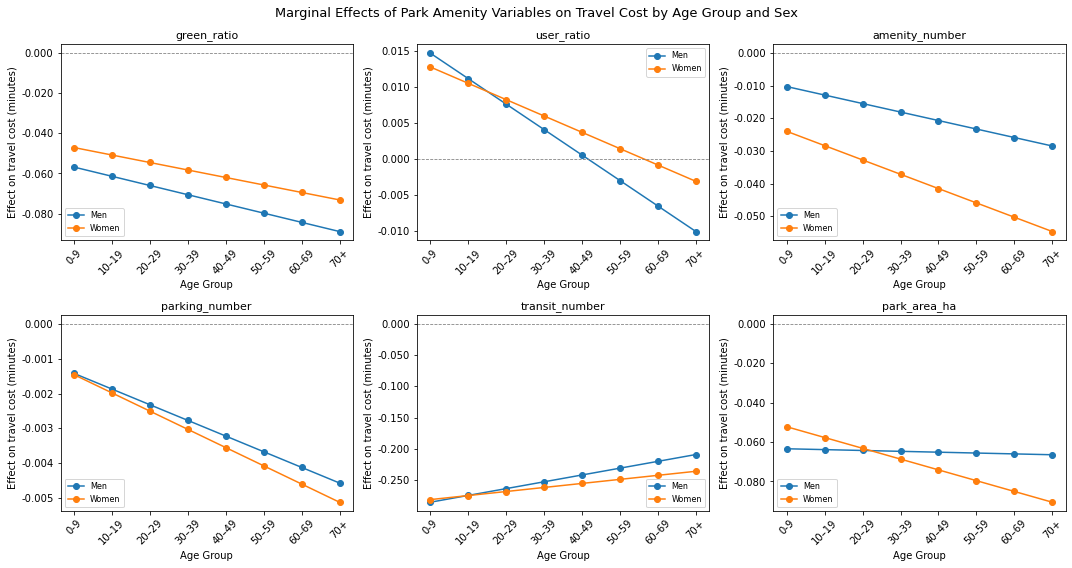


Plot saved: marginal_effects_with_FE.png


In [91]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, var in enumerate(amenities):
    ax = axes[i]
    sub = marginal_table[marginal_table["Amenity"] == var]

    ax.plot(sub["AgeGroup"], sub["Men_Effect"],   marker="o", label="Men")
    ax.plot(sub["AgeGroup"], sub["Women_Effect"], marker="o", label="Women")
    ax.axhline(0, linestyle="--", color="gray", linewidth=0.8)

    ax.set_title(var, fontsize=11)
    ax.set_ylabel("Effect on travel cost (minutes)")
    ax.set_xlabel("Age Group")
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
    ax.legend(fontsize=8)

plt.suptitle("Marginal Effects of Park Amenity Variables on Travel Cost by Age Group and Sex", fontsize=13)
plt.tight_layout()
plt.savefig("marginal_effects_with_FE.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nPlot saved: marginal_effects_with_FE.png")

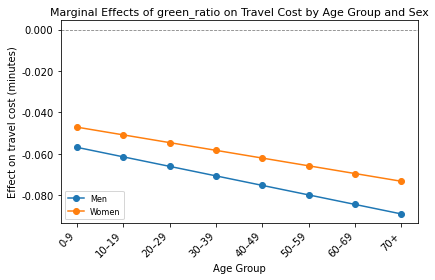

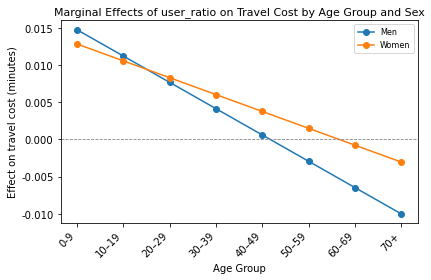

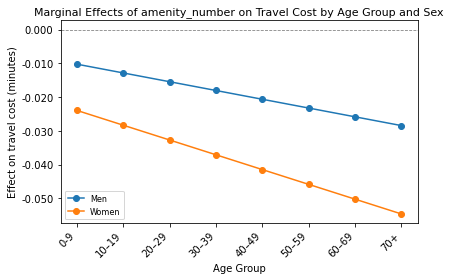

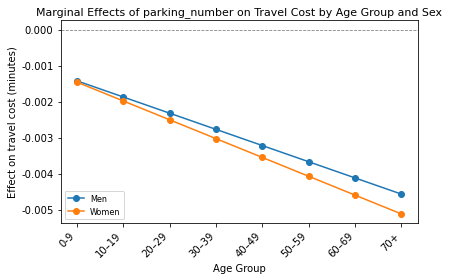

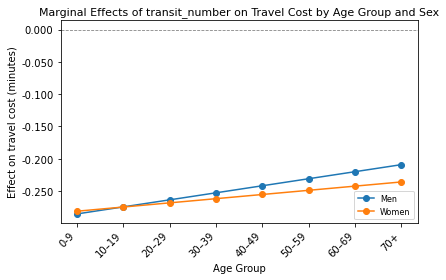

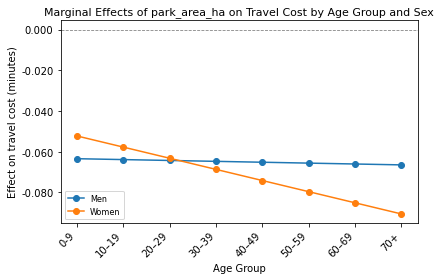

In [107]:
for var in amenities:
    sub = marginal_table[marginal_table["Amenity"] == var]

    plt.figure(figsize=(6, 4))
    plt.plot(sub["AgeGroup"], sub["Men_Effect"],   marker="o", label="Men")
    plt.plot(sub["AgeGroup"], sub["Women_Effect"], marker="o", label="Women")
    plt.axhline(0, linestyle="--", color="gray", linewidth=0.8)
    plt.title(f"Marginal Effects of {var} on Travel Cost by Age Group and Sex", fontsize=11)
    plt.ylabel("Effect on travel cost (minutes)")
    plt.xlabel("Age Group")
    plt.xticks(rotation=45, ha="right")
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
    plt.legend(fontsize=8)
    plt.tight_layout()
    #plt.savefig(f"marginal_effect_{var}.png", dpi=150, bbox_inches="tight")
    plt.show()
    #print(f"Plot saved: marginal_effect_{var}.png")

In [105]:
import os
print(os.getcwd())

C:\Users\ohdaw\OneDrive - Harvard University\carole_meetings\RA\codes


# Gender and Age Gap in Marginal Effect

In [98]:
age_groups = {
    "0-9": 5,
    "10–19": 15,
    "20–29": 25,
    "30–39": 35,
    "40–49": 45,
    "50–59": 55,
    "60–69": 65,
    "70+":   75
}

In [99]:
def marginal_effect(res, var, age, female):
    """
    Marginal effect of park variable var at given age and sex.
    female = 0 (men), 1 (women)
    """
    b   = res.params[var]
    bf  = res.params[f"{var}_F"]
    ba  = res.params[f"{var}_A"]
    bfa = res.params[f"{var}_FA"]

    return b + female*bf + age*ba + female*age*bfa

In [100]:
rows = []

#amenities = ["geen_ratio", "user_ratio", "amenity_number", "parking_number","transit_number", "park_area_ha"]

for var in amenities:  #["park_area","amenity_number","parking_number","transit_number"]
    for label, age in age_groups.items():

        me_m = marginal_effect(res, var, age, female=0)
        me_w = marginal_effect(res, var, age, female=1)

        rows.append({
            "Amenity": var,
            "AgeGroup": label,
            "AgeMid": age,
            "Men_Effect": me_m,
            "Women_Effect": me_w,
            "W_minus_M": me_w - me_m
        })

marginal_table = pd.DataFrame(rows)
print(marginal_table.head())

       Amenity AgeGroup  AgeMid  Men_Effect  Women_Effect  W_minus_M
0  green_ratio      0-9       5   -0.056803     -0.047063   0.009740
1  green_ratio    10–19      15   -0.061398     -0.050796   0.010601
2  green_ratio    20–29      25   -0.065992     -0.054530   0.011462
3  green_ratio    30–39      35   -0.070587     -0.058264   0.012323
4  green_ratio    40–49      45   -0.075182     -0.061997   0.013185


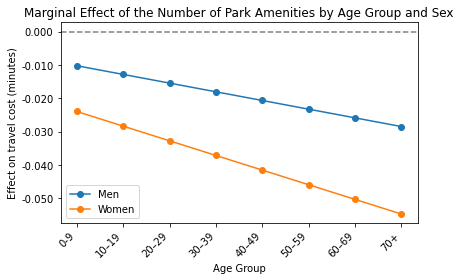

In [101]:
var = "amenity_number"
sub = marginal_table[marginal_table["Amenity"] == var]

plt.figure()
plt.plot(sub["AgeGroup"], sub["Men_Effect"], marker="o", label="Men")
plt.plot(sub["AgeGroup"], sub["Women_Effect"], marker="o", label="Women")
plt.axhline(0, linestyle="--", color="gray")
plt.title(f"Marginal Effect of the Number of Park Amenities by Age Group and Sex")
plt.ylabel("Effect on travel cost (minutes)")
plt.xlabel("Age Group")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

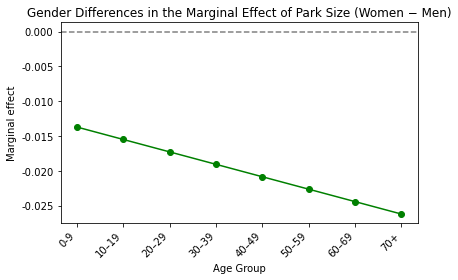

In [102]:
plt.figure()

plt.plot(sub["AgeGroup"], sub["W_minus_M"], marker="o", color="green")
plt.axhline(0, linestyle="--", color="gray")
plt.title(f"Gender Differences in the Marginal Effect of Park Size (Women − Men)")
plt.ylabel("Marginal effect")
plt.xlabel("Age Group")
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))
plt.tight_layout()
plt.show()

In [2]:
import pkg_resources

for pkg in ["rpy2", "pymer4"]:
    try:
        print(f"{pkg}: {pkg_resources.get_distribution(pkg).version}")
    except:
        print(f"{pkg}: NOT FOUND")

rpy2: 3.5.11
pymer4: 0.8.1


In [ ]:
conda install -c conda-forge rpy2=3.5.11 -y